<a href="https://colab.research.google.com/github/suyon0416/26-2_ESAA_YB/blob/main/YB_1127_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C_%EC%B0%A8%EC%9B%90%EC%B6%95%EC%86%8C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 데이터 로드
from sklearn.datasets import fetch_openml
mnist=fetch_openml('mnist_784', version=1)

In [2]:
# train, test split
X_train = mnist['data'][:60000]
y_train = mnist['target'][:60000]
X_test = mnist['data'][60000:]
y_test = mnist['target'][60000:]

* 랜덤포레스트에 적용

In [3]:
# 랜덤포레스트에 적용 (n_estimators=10, random_state=42)

from sklearn.ensemble import RandomForestClassifier
import time

rnd_clf = RandomForestClassifier(n_estimators=10, random_state=42)

start = time.time()
rnd_clf.fit(X_train, y_train)
print('학습 시간: {:.2f}초'.format(time.time() - start))

학습 시간: 3.92초


In [4]:
# 정확도 결과

from sklearn.metrics import accuracy_score

y_pred = rnd_clf.predict(X_test)
print('정확도: {:.4f}'.format(accuracy_score(y_test, y_pred)))

정확도: 0.9492


# 1. PCA

* PCA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [5]:
# PCA 라이브러리 불러오기
from sklearn.decomposition import PCA


In [6]:
# PCA 적용 95% : n_components=0.95
pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)

print('PCA 이후 차원 수:', pca.n_components_)


PCA 이후 차원 수: 154


In [7]:
# PCA 이후 랜덤포레스트 훈련
rnd_clf2 = RandomForestClassifier(n_estimators=10, random_state=42)

start = time.time()
rnd_clf2.fit(X_train_reduced, y_train)
print('학습 시간: {:.2f}초'.format(time.time() - start))


학습 시간: 15.43초


In [8]:
# 정확도 결과 (X_test도 PCA 적용해야합니다.)
X_test_reduced = pca.transform(X_test)   # fit 없이 transform만!

y_pred = rnd_clf2.predict(X_test_reduced)
print('정확도: {:.4f}'.format(accuracy_score(y_test, y_pred)))


정확도: 0.8925


**관련 문제**

* PCA모델을 와인 데이터셋에 적용하여 차원을 축소하고 그 결과를 그래프로 나타내보세요.

(1) 필요한 모듈 불러오기

In [9]:
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

(2)  load_wine을 사용해 데이터셋을 생성한다.

In [10]:
wine = load_wine()
X = wine.data
y = wine.target

df = pd.DataFrame(X, columns=wine.feature_names)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


(3) X에 표준 스케일링(Standard scaling)을 적용하여 X_scaled을 생성한다.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

(4) PCA 모델을 X에 적용하여 2개의 차원으로 추출한다. 단, random_state=1234로 설정한다.

In [12]:
#PCA 모델을 X_scaled에 적용하여 2개의 차원으로 추출한다.
pca = PCA(n_components=2, random_state=1234)
X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)
print('설명 분산 비율:', pca.explained_variance_ratio_)




(178, 2)
설명 분산 비율: [0.36198848 0.1920749 ]


(5) 추출한 피처를 그래프로 나타내라.

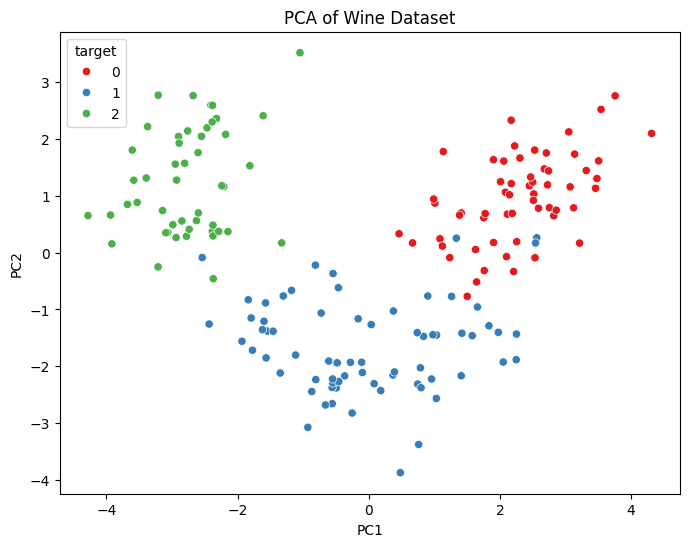

In [13]:
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['target'] = y

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='target', palette='Set1')
plt.title('PCA of Wine Dataset')
plt.show()

# 2. LDA

- LDA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [14]:
# LDA 라이브러리 불러오기
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


In [15]:
# LDA 적용 : n_components=5
lda = LinearDiscriminantAnalysis(n_components=5)
X_train_lda = lda.fit_transform(X_train, y_train)   # PCA와 달리 y_train도 넣어야 함!

print('LDA 이후 차원 수:', X_train_lda.shape)


LDA 이후 차원 수: (60000, 5)


In [16]:
# LDA 이후 랜덤포레스트 훈련
rnd_clf3 = RandomForestClassifier(n_estimators=10, random_state=42)

start = time.time()
rnd_clf3.fit(X_train_lda, y_train)
print('학습 시간: {:.2f}초'.format(time.time() - start))


학습 시간: 2.37초


In [17]:
# 정확도 결과 (X_test도 LDA 적용해야합니다.)
X_test_lda = lda.transform(X_test)   # fit 없이 transform만!

y_pred = rnd_clf3.predict(X_test_lda)
print('정확도: {:.4f}'.format(accuracy_score(y_test, y_pred)))# 정확도 결과 (X_test도 LDA 적용해야합니다.)


정확도: 0.8301
